# UTS Graf Sains Data
Periode: P1 (training) = 01-15 Juli 2015 | P2 (testing) = 01-15 Agustus 2015 (UTC)

P1 dipakai untuk membangun graf dan "belajar" selera pengguna. P2 dipakai sebagai "kunci jawaban" untuk menguji apakah rekomendasi dari P1 benar-benar terjadi di bulan berikutnya. Dengan memisahkan keduanya, kita menguji rekomendasi pada data yang belum pernah dilihat saat membangun model.


## 0. Setup dan konfigurasi

In [1]:
import pandas as pd
df = pd.read_csv("data/events.csv")
print(df.dtypes)
df.head()

timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


Neo4j Driver menghubungkan aplikasi Python dengan database Neo4j. Melalui driver, Python dapat menjalankan query Cypher untuk membuat simpul dan relasi serta membaca data dari graf.

In [ ]:
import os, math
import numpy as np, pandas as pd, scipy.sparse as sp
import networkx as nx, matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from neo4j import GraphDatabase

DATA_DIR = "data"
URI, AUTH, DB = "neo4j://127.0.0.1:7687", ("neo4j", "uts12345"), "neo4j"
SEED = 42

P1 = ("2015-07-01", "2015-07-16")   # [start, end) -> 1-15 Juli 2015 inklusif
P2 = ("2015-08-01", "2015-08-16")   # [start, end) -> 1-15 Agustus 2015 inklusif
W = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}   # bobot implicit feedback

os.makedirs(DATA_DIR, exist_ok=True)

URI dan kredensial disesuaikan dengan konfigurasi Neo4j yang digunakan. Pada notebook ini kredensial yang dipakai adalah neo4j://127.0.0.1:7687 dengan pengguna neo4j.


### Jawaban Pertanyaan Pendahuluan (Checkpoint) 1.2

1. Apa nama database yang digunakan pada tutorial ini? Yaitu `neo4j`, terlihat dari parameter `database_="neo4j"` pada `execute_query`
2. Sebutkan akses lain untuk mengakses database lain dalam 1 instance. Pakai perintah Cypher **`USE namadb`** (di Neo4j Query ditulis `:use namadb`). Lewat driver Python bisa dengan mengganti parameter `database_="namadb"` atau `driver.session(database="namadb")`. Perintah pendukung: `SHOW DATABASES` untuk melihat daftar database dan `CREATE DATABASE namadb` untuk membuat database baru.
3. Apa jenis graf pertemanan yang dibuat? Graf berarah (directed), simpulnya berlabel `Person` dengan properti `name`, dan relasi `KNOWS` mengarah dari Arthur ke Guinevere, Lancelot, dan Merlin, sehingga bentuknya bintang (star) dengan Arthur sebagai pusat. Karena memakai `MERGE`, menjalankan kode berkali-kali tidak membuat simpul atau relasi ganda.

## 2.1 No. 1-2: Filter periode waktu dan simpan ke CSV

In [3]:
df = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
print(df.shape)
print("Rentang data:", df["dt"].min(), "->", df["dt"].max())
print(df["event"].value_counts())

(2756101, 6)
Rentang data: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [4]:
def window(df, start, end):
    s, e = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC")
    return df[(df["dt"] >= s) & (df["dt"] < e)].drop(columns="dt")

p1 = window(df, *P1)
p2 = window(df, *P2)
p1.to_csv(os.path.join(DATA_DIR, "events_p1.csv"), index=False)
os.makedirs("data_p1", exist_ok=True)
p1.to_csv(os.path.join("data_p1", "events.csv"), index=False)   # untuk import_events.py
p2.to_csv(os.path.join(DATA_DIR, "events_p2.csv"), index=False)

for name, d in [("P1", p1), ("P2", p2)]:
    print(name, "| baris:", len(d), "| user:", d.visitorid.nunique(), "| item:", d.itemid.nunique())
    print(d.event.value_counts().to_dict())

P1 | baris: 333778 | user: 185205 | item: 87308
{'view': 322990, 'addtocart': 8099, 'transaction': 2689}
P2 | baris: 265509 | user: 153836 | item: 76078
{'view': 256371, 'addtocart': 7047, 'transaction': 2091}


Dari data asli 2.756.101 baris (3 Mei sampai 18 September 2015), P1 hanya mengambil sebagian kecil. Di P1, aktivitas `view` sangat dominan (322.990 baris, sekitar 96,8%), sedangkan `addtocart` hanya 8.099 (sekitar 2,4%) dan `transaction` hanya 2.689 (sekitar 0,8%). Ini wajar untuk toko online: banyak orang melihat produk, sedikit yang memasukkan ke keranjang, dan lebih sedikit lagi yang membeli.

Hasil filter disimpan ke `events_p1.csv` dan `events_p2.csv`. Hanya data P1 yang diimpor ke Neo4j. Data P2 tidak dimasukkan ke graf dan hanya dipakai saat evaluasi (Hit@5 dan NDCG@5).

## Koneksi ke Neo4j (untuk query)

In [7]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def run(q, **params):
    recs, _, _ = driver.execute_query(q, parameters_=params, database_=DB)
    return pd.DataFrame([r.data() for r in recs])

## 2.1 No. 3: Komposisi subgraph
Penjelasan Cypher: `MATCH (n)` mengambil semua simpul, `labels(n)` memberi label, `count(n)` menghitung per label. `MATCH ()-[r]->()` + `type(r)` menghitung relasi per tipe.

In [8]:
nodes = run("MATCH (n) RETURN labels(n)[0] AS label, count(n) AS jumlah ORDER BY jumlah DESC")
rels  = run("MATCH ()-[r]->() RETURN type(r) AS tipe_relasi, count(r) AS jumlah ORDER BY jumlah DESC")
display(nodes); display(rels)

,label,jumlah
0,Visitor,185205
1,Item,87308


,tipe_relasi,jumlah
0,VIEWED,322990
1,ADDED_TO_CART,8099
2,BOUGHT,2689


Graf ini adalah graf bipartit yang mana hanya ada dua jenis simpul (user dan item), dan semua panah selalu dari user ke item (tidak ada user ke user atau item ke item). Total relasi 322.990 + 8.099 + 2.689 = 333.778, sama persis dengan jumlah baris data P1, jadi tidak ada data yang hilang saat diimpor. Jumlah user (185 ribu) hampir dua kali lipat jumlah item (87 ribu), artinya rata-rata satu item dilihat oleh lebih banyak orang dibanding jumlah item yang dilihat satu orang.

## 2.1 No. 4-5: Vector Space Model (VSM)
Matriks user-item `R` (baris = Visitor, kolom = Item), nilai = jumlah event x bobot (view=1, addtocart=3, transaction=5). VSM Item = transpos `R`.

Vector Space Model adalah cara mengubah data menjadi angka berbentuk vektor supaya bisa dihitung kemiripannya. Di sini kita membuat tabel besar (matriks) bernama `R`: setiap baris adalah satu user, setiap kolom adalah satu item, dan isi sel menunjukkan seberapa kuat user itu berinteraksi dengan item tersebut. Kekuatannya dihitung dari jumlah interaksi dikali bobot: `view` = 1, `addtocart` = 3, `transaction` = 5 (membeli dianggap sinyal paling kuat). Bobot ini adalah asumsi yang saya pilih. Sel yang kosong berarti 0 (user tidak pernah berinteraksi dengan item itu).

In [9]:
edges = run("""
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(r) AS c
""")
edges["w"] = edges["t"].map(W) * edges["c"]
edges = edges.groupby(["u", "i"], as_index=False)["w"].sum()

u_codes, u_ids = pd.factorize(edges["u"])
i_codes, i_ids = pd.factorize(edges["i"])
u_ids, i_ids = u_ids.to_numpy(), i_ids.to_numpy()

R  = sp.csr_matrix((edges["w"].values, (u_codes, i_codes)), shape=(len(u_ids), len(i_ids)))   # VSM User
RT = R.T.tocsr()                                                                              # VSM Item

In [10]:
def describe(M, name, row_name, col_name):
    n, m = M.shape
    deg = np.diff(M.indptr)
    print(f"== {name} ==")
    print(f"shape       : {M.shape}  ({n} {row_name} x {m} {col_name})")
    print(f"dimensi     : {M.ndim}D, tiap {row_name} = vektor {m} dimensi")
    print(f"non-zero    : {M.nnz}  | density = {M.nnz/(n*m):.6%} | sparsity = {1-M.nnz/(n*m):.6%}")
    print(f"rata2 non-zero per baris: {deg.mean():.2f} | median {np.median(deg):.0f} | max {deg.max()}")
    print(f"memori sparse: {(M.data.nbytes+M.indices.nbytes+M.indptr.nbytes)/1e6:.1f} MB | dense (float64) ~ {n*m*8/1e9:.1f} GB")

describe(R,  "VSM User (user x item)", "user", "item")
describe(RT, "VSM Item (item x user)", "item", "user")

== VSM User (user x item) ==
shape       : (185205, 87308)  (185205 user x 87308 item)
dimensi     : 2D, tiap user = vektor 87308 dimensi
non-zero    : 266342  | density = 0.001647% | sparsity = 99.998353%
rata2 non-zero per baris: 1.44 | median 1 | max 888
memori sparse: 3.9 MB | dense (float64) ~ 129.4 GB
== VSM Item (item x user) ==
shape       : (87308, 185205)  (87308 item x 185205 user)
dimensi     : 2D, tiap item = vektor 185205 dimensi
non-zero    : 266342  | density = 0.001647% | sparsity = 99.998353%
rata2 non-zero per baris: 3.05 | median 1 | max 410
memori sparse: 3.5 MB | dense (float64) ~ 129.4 GB


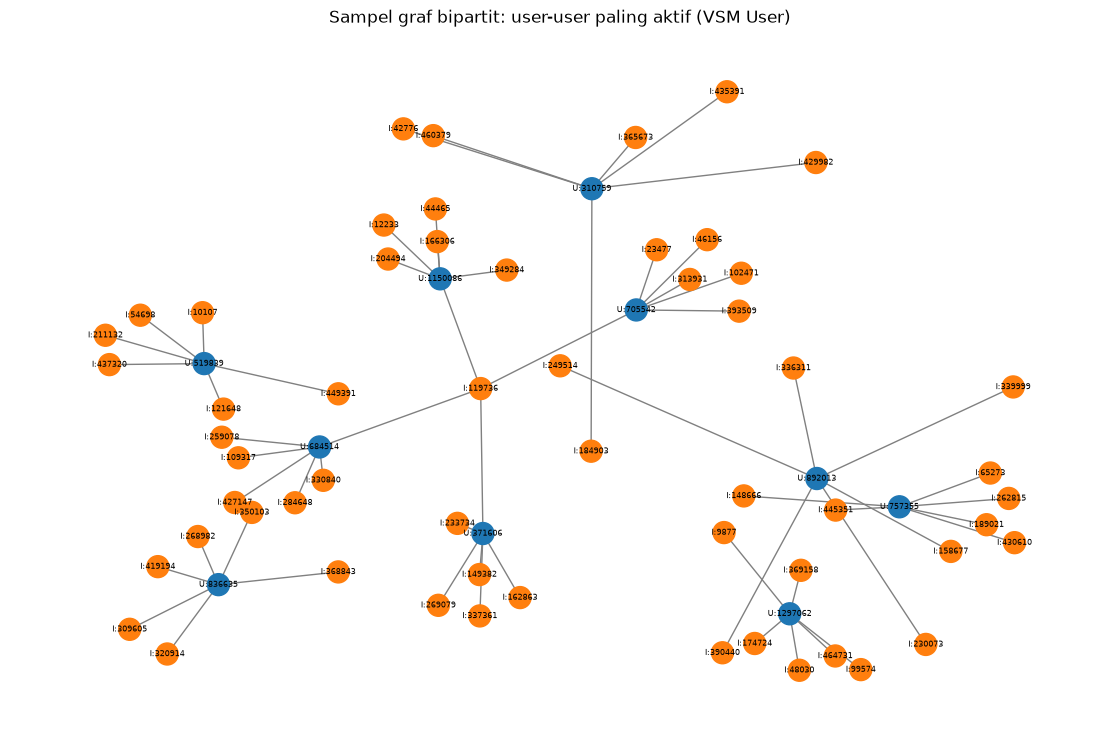

simpul: 67 | sisi: 60


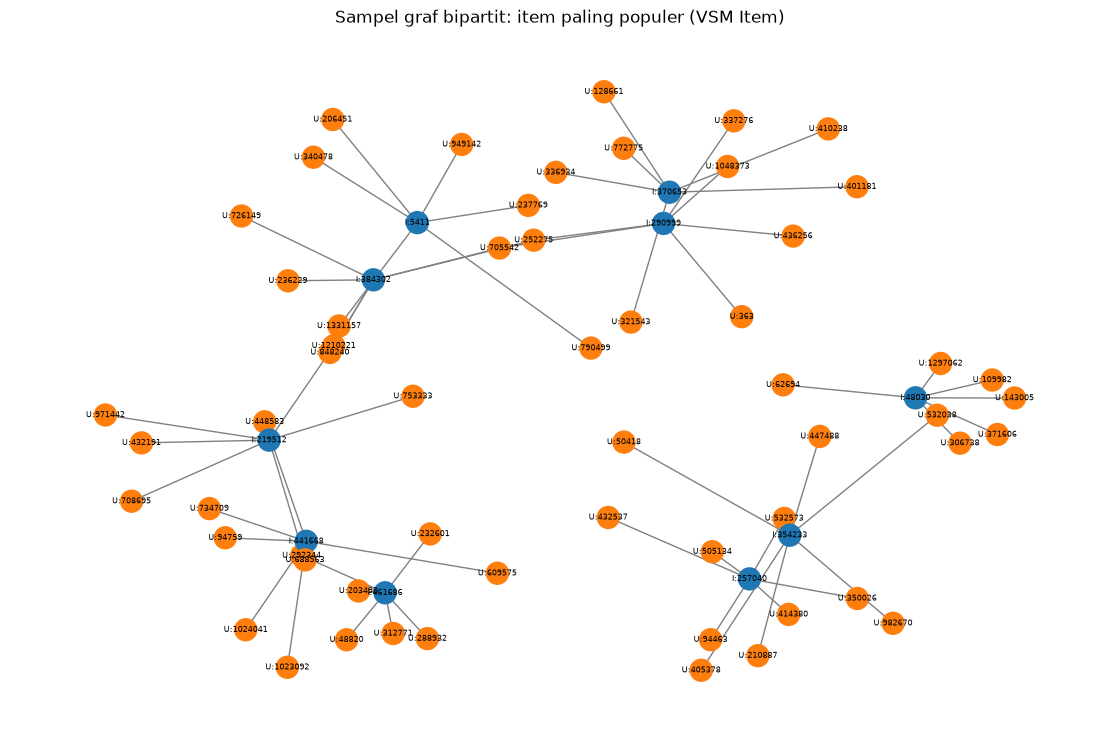

simpul: 67 | sisi: 60


In [11]:
def plot_sample(M, row_ids, col_ids, rname, cname, n_rows=10, per_row=6, title=""):
    deg = np.diff(M.indptr)
    top = np.argsort(-deg)[:n_rows]
    G = nx.Graph()
    for r in top:
        row = M[r]
        for c in row.indices[np.argsort(-row.data)[:per_row]]:
            G.add_edge(f"{rname}:{row_ids[r]}", f"{cname}:{col_ids[c]}", weight=M[r, c])
    pos = nx.spring_layout(G, seed=SEED, k=0.6)
    colors = ["tab:blue" if n.startswith(rname) else "tab:orange" for n in G]
    plt.figure(figsize=(11, 7))
    nx.draw(G, pos, node_color=colors, node_size=250, with_labels=True, font_size=6, edge_color="gray")
    plt.title(title); plt.show()
    print("simpul:", G.number_of_nodes(), "| sisi:", G.number_of_edges())

plot_sample(R,  u_ids, i_ids, "U", "I", title="Sampel graf bipartit: user-user paling aktif (VSM User)")
plot_sample(RT, i_ids, u_ids, "I", "U", title="Sampel graf bipartit: item paling populer (VSM Item)")

Setiap user adalah satu vektor.
- Shape: 185.205 x 87.308 (185.205 user x 87.308 item).
- Dimensi: setiap user digambarkan dengan vektor 87.308 angka (satu angka untuk tiap item).
- Isi tidak nol (non-zero): 266.342 sel, artinya hanya 266.342 pasangan user-item yang pernah berinteraksi.
- Kepadatan (density) hanya 0,001647% atau sparsity 99,998% hampir seluruh tabel berisi nol.
- Rata-rata satu user hanya berinteraksi dengan 1,44 item (median 1, paling banyak 888 item).

setiap item adalah satu vektor.
- Shape: 87.308 x 185.205 (87.308 item x 185.205 user).
- Dimensi: setiap item digambarkan dengan vektor 185.205 angka (satu angka untuk tiap user).
- Isi tidak nol dan sparsity sama dengan VSM User (karena tabelnya sama, hanya diputar).
- Rata-rata satu item disentuh oleh 3,05 user (median 1, paling banyak 410 user).

Plot networkx: Graf penuh (185 ribu user dan 87 ribu item) tidak mungkin digambar secara jelas, jadi yang diplot hanyalah sampel 10 simpul paling aktif beserta maksimal 6 tetangga terkuatnya (total 67 simpul dan 60 sisi). Gambar tersebt memperlihatkan bentuk bipartit (user di satu sisi, item di sisi lain, garis hanya menghubungkan user dengan item) dan adanya beberapa "hub", yaitu simpul yang punya banyak sambungan.

Kesimpulannya Data bersifat sangat jarang (sparse) kebanyakan user hanya menyentuh satu atau dua item. Ini merupakan tantangan utama sistem rekomendasi di dataset ini, karena sedikitnya riwayat membuat sulit menemukan user lain yang benar-benar mirip.

## 2.1 No. 6: Proyeksi mana yang lebih baik?


Graf asli menghubungkan user dengan item, "Memproyeksikan" berarti membuat graf baru yang hanya berisi satu jenis simpul. Proyeksi user-user menghubungkan dua user kalau keduanya menyentuh item yang sama, proyeksi item-item menghubungkan dua item kalau keduanya disentuh oleh user yang sama.


In [12]:
du = np.diff(R.indptr).astype(np.int64)    # jumlah item per user
di = np.diff(RT.indptr).astype(np.int64)   # jumlah user per item
pairs_user_proj = (di * (di - 1) // 2).sum()
pairs_item_proj = (du * (du - 1) // 2).sum()
cmp = pd.DataFrame({
    "proyeksi": ["User-User", "Item-Item"],
    "jumlah simpul": [len(u_ids), len(i_ids)],
    "matriks penuh n x n": [len(u_ids)**2, len(i_ids)**2],
    "batas atas pasangan non-zero": [pairs_user_proj, pairs_item_proj],
    "rata2 tetangga potensial/baris": [R.shape[1] and du.mean(), di.mean()],
})
display(cmp)
print("User dengan 1 interaksi saja:", f"{(du==1).mean():.1%}", "| Item dengan 1 interaksi saja:", f"{(di==1).mean():.1%}")

,proyeksi,jumlah simpul,matriks penuh n x n,batas atas pasangan non-zero,rata2 tetangga potensial/baris
0,User-User,185205,34300892025,1674522,1.438093
1,Item-Item,87308,7622686864,2256151,3.050602


User dengan 1 interaksi saja: 83.1% | Item dengan 1 interaksi saja: 52.9%


**Perbandingan angka dari data P1**

| Ukuran | User-User | Item-Item |
|---|---|---|
| Jumlah simpul | 185.205 | 87.308 |
| Ukuran tabel kemiripan penuh (n x n) | sekitar 34,3 miliar | sekitar 7,6 miliar |
| Batas atas pasangan yang mungkin punya kemiripan | 1.674.522 | 2.256.151 |
| Rata-rata interaksi per baris | 1,44 | 3,05 |
| Baris yang hanya punya 1 interaksi | 83,1% | 52,9% |

Dari sisi efisiensi (hemat sumber daya):
- Proyeksi user-user menghasilkan lebih sedikit pasangan yang punya kemiripan (1,67 juta dibanding 2,26 juta), sehingga hasil kemiripan yang harus disimpan lebih sedikit.
- Proyeksi item-item punya lebih sedikit simpul (87 ribu dibanding 185 ribu), sehingga tabel penuhnya sekitar 4,5 kali lebih kecil.
- Dari sisi efisiensi, kedua proyeksi relatif seimbang, dengan keunggulan masing-masing.

Dari sisi efektivitas (kualitas informasi):
- Di proyeksi user-user 83,1% user hanya punya satu interaksi, sehingga vektornya sangat tipis dan sulit dibandingkan dengan user lain.
- Di proyeksi item-item rata-rata tiap item disentuh 3,05 user dan "hanya" 52,9% item yang punya satu interaksi, sehingga vektornya lebih tebal dan kemiripannya lebih bisa diandalkan.
- Jadi dari sisi efektivitas, item-item lebih unggul.


## 2.1 No. 7: Similarity pada graf terproyeksi (cosine)


Cosine similarity mengukur seberapa searah dua vektor, rentang nilainya antara 0 (sama sekali tidak mirip) sampai 1 (identik). Rumusnya: `cos(u, v) = (u . v) / (||u|| x ||v||)`, yaitu perkalian titik dua vektor dibagi hasil kali panjang masing-masing. Alasan memakai cosine karena ia tidak terpengaruh oleh banyaknya total interaksi user, hanya melihat kemiripan pola. Dua user yang sama-sama menyukai item yang sama akan bernilai tinggi walaupun yang satu lebih aktif dari yang lain.


Cara memilih user acuan secara acak dan bisa diulang (reproducible)
1. Ambil user yang punya minimal 3 item di P1 dan juga aktif di P2 (supaya nanti ada data pembanding untuk evaluasi), Jumlahnya 769 user.
2. Urutkan kandidat, lalu pilih satu dengan `numpy.random.default_rng(42).choice(...)`. Seed 42, sehingga siapa pun yang menjalankan ulang akan mendapat user yang sama.
3. Hasilnya adalah user acuan = 130999.

In [ ]:
PROJ = "user"

p2_users = set(p2["visitorid"].unique())
deg_u = np.diff(R.indptr)
mask = (deg_u >= 3) & np.isin(u_ids, list(p2_users))
cand = np.sort(u_ids[mask])
rng = np.random.default_rng(SEED)
REF_USER = int(rng.choice(cand))
print("kandidat:", len(cand), "| REF_USER =", REF_USER)

if PROJ == "user":
    M, ids, REF, label, key = R, u_ids, REF_USER, "Visitor", "visitorId"
else:
    deg_i = np.diff(RT.indptr)
    cand_i = np.sort(i_ids[deg_i >= 5])
    REF = int(np.random.default_rng(SEED).choice(cand_i))
    M, ids, label, key = RT, i_ids, "Item", "itemId"
print("PROJ =", PROJ, "| REF =", REF)

def top_similar(M, ids, ref, k=5):
    Mn = normalize(M, norm="l2", axis=1)
    pos = int(np.where(ids == ref)[0][0])
    s = (Mn @ Mn[pos].T).toarray().ravel()
    s[pos] = -1
    top = np.argsort(-s, kind="stable")[:k]
    return [(int(ids[t]), float(s[t])) for t in top]

top5 = top_similar(M, ids, REF, 5)
pd.DataFrame(top5, columns=["neighbor", "cosine"])

kandidat: 769 | REF_USER = 130999
PROJ = user | REF = 130999


,neighbor,cosine
0,456456,0.218218
1,687595,0.218218
2,903570,0.218218
3,1099581,0.218218
4,1277733,0.218218


Kelima hasilnya nilainya sama persis (0,2182), artinya urutan di antara mereka seri (tie), dan siapa yang masuk lima besar ditentukan urutan data, bukan karena yang paling mirip. Ini terjadi karena user di dataset ini punya riwayat sangat pendek, sehingga banyak user yang kemiripannya dengan user acuan persis sama.


### Kondisi SEBELUM menulis similarity ke graf (No. 8)

In [20]:
before = run("MATCH ()-[r]->() RETURN type(r) AS tipe_relasi, count(r) AS jumlah ORDER BY tipe_relasi")
display(before)

,tipe_relasi,jumlah
0,ADDED_TO_CART,8099
1,BOUGHT,2689
2,VIEWED,322990


### 7b: tulis nilai similarity ke graf sebagai relasi `SIMILAR_TO`

In [21]:
rows = [{"a": REF, "b": b, "score": s} for b, s in top5]
run(f"""
    UNWIND $rows AS r
    MATCH (a:{label} {{{key}: r.a}}), (b:{label} {{{key}: r.b}})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.score = r.score, s.metric = 'cosine', s.projection = $proj
""", rows=rows, proj=PROJ)

""


### 7a: Cypher untuk 5 record similarity tertinggi

In [22]:
q_top5 = f"""
MATCH (a:{label} {{{key}: $ref}})-[s:SIMILAR_TO]->(b:{label})
RETURN a.{key} AS ref, b.{key} AS neighbor, s.score AS score
ORDER BY score DESC
LIMIT 5
"""
print(q_top5)
display(run(q_top5, ref=REF))


MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS ref, b.visitorId AS neighbor, s.score AS score
ORDER BY score DESC
LIMIT 5



,ref,neighbor,score
0,130999,456456,0.218218
1,130999,687595,0.218218
2,130999,1277733,0.218218
3,130999,1099581,0.218218
4,130999,903570,0.218218


Lima tetangga terdekat user 130999 adalah 456456, 687595, 903570, 1099581, dan 1277733 (masing-masing cosine 0,2182).

## 2.1 No. 8: Sebelum vs sesudah similarity

Sebelum similarity graf hanya berisi tiga jenis relasi interaksi (VIEWED, ADDED_TO_CART, BOUGHT). Sesudah similarity muncul jenis relasi baru `SIMILAR_TO` yang menghubungkan user acuan dengan lima user paling mirip.

,tipe_relasi,sebelum,sesudah
0,ADDED_TO_CART,8099.0,8099
1,BOUGHT,2689.0,2689
2,SIMILAR_TO,0.0,5
3,VIEWED,322990.0,322990


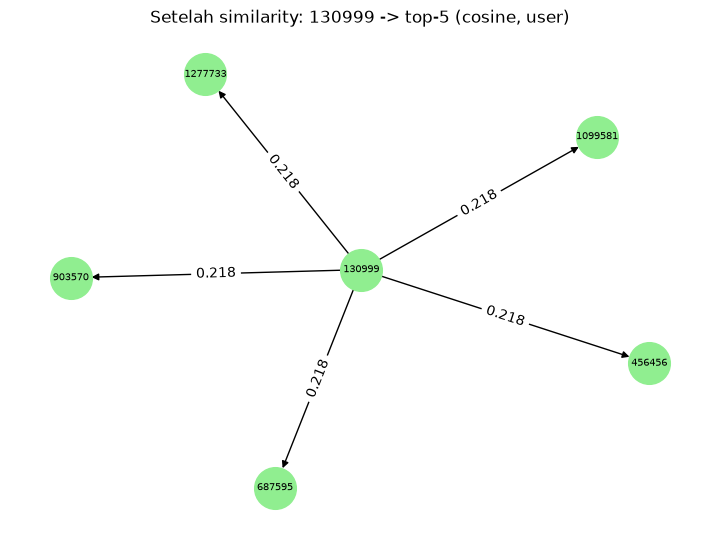

In [23]:
after = run("MATCH ()-[r]->() RETURN type(r) AS tipe_relasi, count(r) AS jumlah ORDER BY tipe_relasi")
display(before.rename(columns={"jumlah": "sebelum"}).merge(after.rename(columns={"jumlah": "sesudah"}), on="tipe_relasi", how="outer").fillna(0))

G = nx.DiGraph()
for b, s in top5:
    G.add_edge(f"{REF}", f"{b}", score=round(s, 3))
pos = nx.spring_layout(G, seed=SEED)
plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=True, node_color="lightgreen", node_size=900, font_size=7)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "score"))
plt.title(f"Setelah similarity: {REF} -> top-5 (cosine, {PROJ})"); plt.show()

Jumlah relasi interaksi tidak berubah sama sekali, hanya bertambah 5 relasi `SIMILAR_TO`. Artinya similarity tidak mengubah data asli, ia hanya menambah "lapisan informasi" baru di atas graf, yaitu hubungan kemiripan antar user. Gambar graf sebelum dan sesudah dapat dilihat di screenshot (`n5_sebelum.png` dan `n5b_sesudah.png`): sebelumnya satu user terhubung ke item-itemnya, sesudahnya satu user terhubung ke lima user lain beserta nilai kemiripannya.

## 2.2 Analytics


Ide dasarnya "Orang yang selera belanjanya mirip denganmu kemungkinan menyukai barang yang juga kamu suka." Jadi untuk merekomendasikan item ke satu user, kita cari user lain yang paling mirip (tetangga terdekat), lalu kita ambil item yang mereka sentuh tetapi belum pernah disentuh user target.

User target dipilih dengan `numpy.random.default_rng(42)` dari 769 user yang punya minimal 3 item di P1 dan aktif di P2, hasilnya adalah user 130999.

In [24]:
uid2row = {int(u): r for r, u in enumerate(u_ids)}
Rn = normalize(R, norm="l2", axis=1)
popularity = np.asarray((R > 0).sum(axis=0)).ravel()
pop_order = np.argsort(-popularity, kind="stable")

def recommend(target, k=5, n=5):
    r = uid2row[int(target)]
    sims = (Rn @ Rn[r].T).toarray().ravel()
    sims[r] = -1
    nbr = np.argsort(-sims, kind="stable")[:k]
    seen = set(R[r].indices)
    scores = {}
    for b in nbr:
        if sims[b] <= 0:
            continue
        row = R[b]
        for j, w in zip(row.indices, row.data):
            if j not in seen:
                scores[j] = scores.get(j, 0.0) + sims[b] * w
    ranked = [j for j, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))][:n]
    fallback = 0
    for j in pop_order:                      # isi dengan item populer jika kandidat kurang
        if len(ranked) >= n: break
        if j not in seen and j not in ranked:
            ranked.append(j); fallback += 1
    neighbors = [(int(u_ids[b]), round(float(sims[b]), 4)) for b in nbr]
    return [int(i_ids[j]) for j in ranked], neighbors, fallback

recs, neighbors, fb = recommend(REF_USER, k=5, n=5)
print("User target      :", REF_USER)
print("5 tetangga (id, cosine):", neighbors)
print("Top-5 rekomendasi:", recs, "| diisi popularitas:", fb)
print("3 item DIIKLANKAN :", recs[:3])

User target      : 130999
5 tetangga (id, cosine): [(456456, 0.2182), (687595, 0.2182), (903570, 0.2182), (1099581, 0.2182), (1277733, 0.2182)]
Top-5 rekomendasi: [5411, 461686, 257040, 370653, 384302] | diisi popularitas: 5
3 item DIIKLANKAN : [5411, 461686, 257040]


(a) Langkah-langkah skrip KNN (k = 5)**
1. Hitung cosine similarity antara user target dan semua user lain.
2. Ambil 5 tetangga terdekat (k = 5), tidak termasuk dirinya sendiri.
3. Kumpulkan item yang disentuh tetangga tetapi belum pernah disentuh user target.
4. Beri skor tiap item: jumlah dari (similarity tetangga x bobot interaksi tetangga pada item itu). Item yang disentuh banyak tetangga yang sangat mirip, dan dibeli (bukan sekadar dilihat), mendapat skor lebih tinggi.
5. Urutkan skor, ambil 5 item teratas sebagai rekomendasi.
6. Kalau kandidat kurang dari 5, sisanya diisi item yang paling populer (banyak disentuh user) yang belum pernah disentuh target.

(b) Hasil untuk k = 5
- Lima tetangga: 456456, 687595, 903570, 1099581, 1277733 (similarity masing-masing 0,2182).
- Lima rekomendasi teratas: 5411, 461686, 257040, 370653, 384302.
- Tiga item yang diiklankan: 5411, 461686, 257040.

Output program menunjukkan "diisi popularitas: 5", artinya kelima rekomendasi berasal dari cadangan popularitas, bukan dari tetangga. Penyebabnya adalah para tetangga tidak memiliki item baru yang belum pernah dilihat user 130999 (kemiripan mereka hanya karena item yang sama-sama sudah pernah disentuh). Jadi rekomendasi untuk user ini sebenarnya adalah rekomendasi "item terpopuler".

### Hit@5 dan NDCG@5
Ground truth = item yang berinteraksi dengan user target di P2. Hit@5 bernilai 1 jika setidaknya satu item relevan muncul pada lima rekomendasi teratas, dan 0 jika tidak.

Item yang benar-benar disentuh user 130999 pada periode P2 (Agustus 2015) hanya 1 item, yaitu 268979. Item yang disentuh dianggap "relevan" (relevan = 1, selain itu 0).

Arti metrik
- Hit@5: "apakah minimal satu item relevan masuk dalam 5 rekomendasi teratas?" Nilainya 1 kalau ya, 0 kalau tidak.
- NDCG@5: menilai bukan hanya apakah item relevan ada, tetapi juga di urutan berapa, tem relevan di urutan paling atas mendapat nilai lebih tinggi daripada di urutan bawah. Rumus: `NDCG@5 = DCG@5 / IDCG@5`, dengan `DCG = jumlah dari (relevansi / log2(urutan + 1))`. Nilainya antara 0 sampai 1, dan 1 berarti urutannya sudah ideal.


In [25]:
truth = set(p2.loc[p2["visitorid"] == REF_USER, "itemid"].astype(int))
print("Ground truth P2:", len(truth), "item ->", sorted(truth)[:20])

def hit_at_k(recs, truth, k=5):
    return int(any(i in truth for i in recs[:k]))

def ndcg_at_k(recs, truth, k=5):
    dcg = sum(1.0 / math.log2(pos + 2) for pos, i in enumerate(recs[:k]) if i in truth)
    idcg = sum(1.0 / math.log2(pos + 2) for pos in range(min(k, len(truth))))
    return dcg / idcg if idcg > 0 else 0.0

print("Hit@5  =", hit_at_k(recs, truth, 5))
print("NDCG@5 =", round(ndcg_at_k(recs, truth, 5), 4))

Ground truth P2: 1 item -> [268979]
Hit@5  = 0
NDCG@5 = 0.0


Karena item 268979 tidak muncul, seluruh rel_i bernilai 0 sehingga DCG@5 = 0. Dengan satu item relevan, IDCG@5 = 1 / log2(2) = 1, sehingga:
NDCG@5 = 0 / 1 = 0,0

Berarti rekomendasi belum berhasil menemukan item yang dipakai user pada periode pengujian. Penyebabnya antara lain keterbatasan interaksi user, rekomendasi yang seluruhnya berasal dari item populer, kemiripan tetangga yang rendah (0,218), serta evaluasi yang baru dilakukan pada satu user. Untuk menilai performa sistem secara menyeluruh, evaluasi perlu dirata-ratakan pada lebih banyak user acak (misalnya 100 user).

In [26]:
os.makedirs("hasil_query", exist_ok=True)

queries = {
    "n1_simpul": "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC",
    "n2_relasi": "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC",
    "n3_top5": "MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor) RETURN a.visitorId AS acuan, b.visitorId AS tetangga, s.score AS similarity ORDER BY similarity DESC LIMIT 5",
    "n4_similarity_tertulis": "MATCH (a:Visitor)-[s:SIMILAR_TO]->(b:Visitor) RETURN a.visitorId AS dari, b.visitorId AS ke, s.score AS skor, s.metric AS metrik, s.projection AS proyeksi",
}

for nama, q in queries.items():
    hasil = run(q, ref=int(REF_USER))
    hasil.to_csv(f"hasil_query/{nama}.csv", index=False)
    print(nama, "->", len(hasil), "baris")
    display(hasil)

n1_simpul -> 2 baris


,jenis_simpul,jumlah
0,Visitor,185205
1,Item,87308


n2_relasi -> 4 baris


,jenis_relasi,jumlah
0,VIEWED,322990
1,ADDED_TO_CART,8099
2,BOUGHT,2689
3,SIMILAR_TO,5


n3_top5 -> 5 baris


,acuan,tetangga,similarity
0,130999,456456,0.218218
1,130999,687595,0.218218
2,130999,1277733,0.218218
3,130999,1099581,0.218218
4,130999,903570,0.218218


n4_similarity_tertulis -> 5 baris


,dari,ke,skor,metrik,proyeksi
0,130999,456456,0.218218,cosine,user
1,130999,687595,0.218218,cosine,user
2,130999,1277733,0.218218,cosine,user
3,130999,1099581,0.218218,cosine,user
4,130999,903570,0.218218,cosine,user


In [ ]:
driver.close()